# Mejora 3: ¿qué variables conocidas antes de la pelea son más importantes para ganar?

Y en particular: **¿la ventaja de estilo sobrevive cuando se controla edad, experiencia y racha?**

- Datos: tabla de la Mejora 1 (`peleas_estilo.csv`, generada en `fighter_analisis.ipynb`), con el
  estilo de cada peleador calculado solo con sus peleas anteriores.
- Una fila por pelea, con un peleador elegido al azar; todas las variables son *peleador menos rival*.
- No se usan estadísticas de la misma pelea (golpes, derribos, etc.): son consecuencia del resultado.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

# Tabla de la Mejora 1: una fila por peleador y pelea (cada pelea aparece dos veces)
peleas_estilo_df = pd.read_csv("peleas_estilo.csv", parse_dates=["fecha"])
print(
    f"Filas: {len(peleas_estilo_df)} | peleas: {peleas_estilo_df['fight_id'].nunique()}"
)
print(
    f"Fechas: {peleas_estilo_df['fecha'].min().date()} a {peleas_estilo_df['fecha'].max().date()}"
)

Filas: 22476 | peleas: 11238
Fechas: 1993-11-12 a 2026-08-08


In [ ]:
# Paso 1: solo peleas desde 2005 donde ambos peleadores tienen estilo (al menos 15 min de historial)
con_estilo = peleas_estilo_df[
    (peleas_estilo_df["fecha"] >= "2005-01-01")
    & peleas_estilo_df["estilo"].notna()
    & peleas_estilo_df["opp_estilo"].notna()
]
print(
    f"Peleas desde 2005 con ambos estilos: {con_estilo['fight_id'].nunique()} "
    f"({len(con_estilo)} filas, dos por pelea)"
)

Peleas desde 2005 con ambos estilos: 5968 (11936 filas, dos por pelea)


In [ ]:
# Paso 2: una fila por pelea, eligiendo AL AZAR (semilla fija) quién es "el peleador".
# Se barajan las filas y se queda la primera de cada pelea; nunca se usa la esquina roja/azul.
modelo_df = (
    con_estilo.sample(frac=1, random_state=42)
    .drop_duplicates("fight_id")
    .sort_values("fecha")
    .reset_index(drop=True)
)
print(
    f"Peleas: {len(modelo_df)} | fight_id repetidos: {modelo_df['fight_id'].duplicated().sum()}"
)
print(
    f"El peleador elegido ganó en el {modelo_df['gano'].mean():.1%} de las peleas (debe estar cerca de 50%)"
)

Peleas: 5968 | fight_id repetidos: 0
El peleador elegido ganó en el 49.5% de las peleas (debe estar cerca de 50%)


In [5]:
# Paso 3: variables, todas como peleador menos rival
modelo_df["dif_edad"] = modelo_df["edad"] - modelo_df["opp_edad"]
modelo_df["dif_alcance"] = modelo_df["alcance_cm"] - modelo_df["opp_alcance_cm"]
modelo_df["dif_altura"] = modelo_df["altura_cm"] - modelo_df["opp_altura_cm"]
modelo_df["dif_experiencia"] = (
    modelo_df["peleas_previas"] - modelo_df["opp_peleas_previas"]
)
modelo_df["dif_racha"] = modelo_df["racha"] - modelo_df["opp_racha"]

# Inactividad: +1 si solo el peleador lleva más de un año sin pelear, -1 si solo el rival, 0 si ninguno o ambos
inactivo = (modelo_df["dias_desde_anterior"] > 365).astype(int)
opp_inactivo = (modelo_df["opp_dias_desde_anterior"] > 365).astype(int)
modelo_df["inactividad"] = inactivo - opp_inactivo

# Guardia: +1 si el peleador es zurdo y el rival diestro, -1 al revés, 0 en otro caso
# (si falta la guardia de alguno, queda vacío y la fila se quitará con los demás faltantes)
zurdo_vs_diestro = (modelo_df["guardia"] == "Southpaw") & (
    modelo_df["opp_guardia"] == "Orthodox"
)
diestro_vs_zurdo = (modelo_df["guardia"] == "Orthodox") & (
    modelo_df["opp_guardia"] == "Southpaw"
)
modelo_df["guardia_dif"] = zurdo_vs_diestro.astype(int) - diestro_vs_zurdo.astype(int)
modelo_df.loc[
    modelo_df["guardia"].isna() | modelo_df["opp_guardia"].isna(), "guardia_dif"
] = np.nan

print(
    modelo_df[["dif_edad", "dif_alcance", "dif_altura", "dif_experiencia", "dif_racha"]]
    .describe()
    .round(2)
)
print()
print("inactividad:", modelo_df["inactividad"].value_counts().sort_index().to_dict())
print(
    "guardia_dif:",
    modelo_df["guardia_dif"].value_counts(dropna=False).sort_index().to_dict(),
)

       dif_edad  dif_alcance  dif_altura  dif_experiencia  dif_racha
count   5962.00      5592.00     5965.00          5968.00    5968.00
mean       0.05         0.20        0.11             0.06      -0.05
std        5.27         8.25        6.32             8.44       2.87
min      -19.54       -27.94      -30.48           -41.00     -14.00
25%       -3.46        -5.08       -5.08            -4.00      -2.00
50%        0.16         0.00        0.00             0.00       0.00
75%        3.54         5.08        5.08             4.00       1.00
max       17.60        33.02       50.80            43.00      17.00

inactividad: {-1: 506, 0: 4925, 1: 537}
guardia_dif: {-1.0: 858, 0.0: 4225, 1.0: 873, nan: 12}


In [7]:
# Paso 4: estilo como tres variables de enfrentamiento con signo
# +1 si el peleador tiene el primer estilo y el rival el segundo, -1 al revés, 0 si no es ese enfrentamiento
def enfrentamiento(estilo_a, estilo_b):
    a_vs_b = (modelo_df["estilo"] == estilo_a) & (modelo_df["opp_estilo"] == estilo_b)
    b_vs_a = (modelo_df["estilo"] == estilo_b) & (modelo_df["opp_estilo"] == estilo_a)
    return a_vs_b.astype(int) - b_vs_a.astype(int)


modelo_df["luchador_vs_striker"] = enfrentamiento("luchador", "striker")
modelo_df["sometedor_vs_striker"] = enfrentamiento("sometedor", "striker")
modelo_df["luchador_vs_sometedor"] = enfrentamiento("luchador", "sometedor")

vars_estilo = ["luchador_vs_striker", "sometedor_vs_striker", "luchador_vs_sometedor"]
for col in vars_estilo:
    print(col, modelo_df[col].value_counts().sort_index().to_dict())
print(
    f"\nPeleas entre el mismo estilo (las tres variables en 0): {(modelo_df[vars_estilo] == 0).all(axis=1).sum()}"
)

luchador_vs_striker {-1: 563, 0: 4795, 1: 610}
sometedor_vs_striker {-1: 557, 0: 4854, 1: 557}
luchador_vs_sometedor {-1: 591, 0: 4805, 1: 572}

Peleas entre el mismo estilo (las tres variables en 0): 2518


In [8]:
# Paso 5: correlación entre alcance y altura
r_niveles = peleas_estilo_df["alcance_cm"].corr(peleas_estilo_df["altura_cm"])
r_diferencias = modelo_df["dif_alcance"].corr(modelo_df["dif_altura"])
print(f"Alcance vs altura del mismo peleador:         r = {r_niveles:.2f}")
print(f"Diferencia de alcance vs diferencia de altura: r = {r_diferencias:.2f}")

# Al modelo entran las DIFERENCIAS, así que el criterio |r| > 0.7 se aplica a ellas
vars_fisicas = (
    ["dif_alcance", "dif_altura"] if abs(r_diferencias) <= 0.7 else ["dif_alcance"]
)
print("Variables físicas en el modelo:", vars_fisicas)

Alcance vs altura del mismo peleador:         r = 0.90
Diferencia de alcance vs diferencia de altura: r = 0.63
Variables físicas en el modelo: ['dif_alcance', 'dif_altura']


In [9]:
# Paso 6: quitar filas con datos faltantes
vars_numericas = ["dif_edad"] + vars_fisicas + ["dif_experiencia", "dif_racha"]
vars_modelo = vars_numericas + ["inactividad", "guardia_dif"] + vars_estilo

print("Faltantes por variable:")
print(modelo_df[vars_modelo].isna().sum()[lambda s: s > 0].to_string())
antes = len(modelo_df)
modelo_df = modelo_df.dropna(subset=vars_modelo).reset_index(drop=True)
print(
    f"\nPeleas: {antes} -> {len(modelo_df)} (se perdieron {antes - len(modelo_df)}, "
    f"{(antes - len(modelo_df)) / antes:.1%})"
)
print(f"El peleador ganó en el {modelo_df['gano'].mean():.1%} de las peleas que quedan")

Faltantes por variable:
dif_edad         6
dif_alcance    376
dif_altura       3
guardia_dif     12

Peleas: 5968 -> 5588 (se perdieron 380, 6.4%)
El peleador ganó en el 49.6% de las peleas que quedan


In [10]:
# Paso 7: estandarizar las variables numéricas (media 0, desviación 1) para comparar coeficientes.
# Las variables -1/0/+1 (inactividad, guardia y estilos) se dejan igual: su coeficiente es el
# efecto de pasar de "sin ventaja" a "con ventaja".
escalador = StandardScaler()
X = modelo_df[vars_modelo].copy()
X[vars_numericas] = escalador.fit_transform(X[vars_numericas])
y = modelo_df["gano"].astype(int)

print(
    "Desviación estándar original de las variables numéricas (1 unidad estandarizada = esto):"
)
print(pd.Series(escalador.scale_, index=vars_numericas).round(2).to_string())
X.describe().round(2)

Desviación estándar original de las variables numéricas (1 unidad estandarizada = esto):
dif_edad           5.24
dif_alcance        8.25
dif_altura         6.25
dif_experiencia    8.45
dif_racha          2.85


,dif_edad,dif_alcance,dif_altura,dif_experiencia,dif_racha,inactividad,guardia_dif,luchador_vs_striker,sometedor_vs_striker,luchador_vs_sometedor
count,5588.00,5588.00,5588.00,5588.00,5588.00,5588.00,5588.00,5588.00,5588.00,5588.00
mean,-0.00,-0.00,-0.00,-0.00,0.00,0.00,0.00,0.01,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,0.41,0.54,0.45,0.43,0.44
min,-3.40,-3.41,-4.89,-4.86,-4.90,-1.00,-1.00,-1.00,-1.00,-1.00
25%,-0.67,-0.64,-0.83,-0.48,-0.33,0.00,0.00,0.00,0.00,0.00
50%,0.02,-0.02,-0.02,-0.00,0.02,0.00,0.00,0.00,0.00,0.00
75%,0.67,0.59,0.79,0.47,0.37,0.00,0.00,0.00,0.00,0.00
max,3.35,3.98,5.26,5.09,5.99,1.00,1.00,1.00,1.00,1.00


In [11]:
# Paso 8: regresión logística con statsmodels. Modelo B = estilo + todas las demás variables
def tabla_logit(resultado):
    tabla = pd.DataFrame(
        {
            "coef": resultado.params,
            "ic_inferior": resultado.conf_int()[0],
            "ic_superior": resultado.conf_int()[1],
            "p_value": resultado.pvalues,
        }
    ).drop(index="const")
    tabla["razon_momios"] = np.exp(tabla["coef"])  # odds ratio
    return tabla.reindex(tabla["coef"].abs().sort_values(ascending=False).index)


modelo_b = sm.Logit(y, sm.add_constant(X)).fit(disp=False)
coef_b = tabla_logit(modelo_b)
print(
    f"Constante: {modelo_b.params['const']:.3f} (debe ser cercana a 0: el peleador se eligió al azar)"
)
print(f"Pseudo R² de McFadden: {modelo_b.prsquared:.3f}")
coef_b.round(3)

Constante: -0.019 (debe ser cercana a 0: el peleador se eligió al azar)
Pseudo R² de McFadden: 0.041


,coef,ic_inferior,ic_superior,p_value,razon_momios
dif_edad,-0.405,-0.469,-0.340,0.000,0.667
inactividad,-0.280,-0.414,-0.146,0.000,0.756
luchador_vs_striker,0.241,0.120,0.362,0.000,1.273
dif_racha,0.178,0.121,0.236,0.000,1.195
dif_experiencia,0.112,0.049,0.175,0.001,1.119
sometedor_vs_striker,0.099,-0.027,0.225,0.124,1.104
guardia_dif,0.091,-0.010,0.191,0.077,1.095
dif_alcance,0.082,0.013,0.152,0.020,1.086
luchador_vs_sometedor,0.019,-0.105,0.144,0.759,1.020
dif_altura,-0.013,-0.083,0.057,0.715,0.987


In [12]:
# Paso 9: Modelo A (solo estilo) contra Modelo B (estilo + demás variables)
modelo_a = sm.Logit(y, sm.add_constant(X[vars_estilo])).fit(disp=False)
coef_a = tabla_logit(modelo_a)

comparacion = pd.DataFrame(
    {
        "coef_A": coef_a["coef"],
        "p_A": coef_a["p_value"],
        "coef_B": coef_b.loc[vars_estilo, "coef"],
        "p_B": coef_b.loc[vars_estilo, "p_value"],
    }
).loc[vars_estilo]
comparacion["cambio_%"] = (comparacion["coef_B"] / comparacion["coef_A"] - 1) * 100
# En % de victorias, para leerlo más fácil: probabilidad de ganar del primer estilo frente al segundo
comparacion["pct_victorias_A"] = 100 / (1 + np.exp(-comparacion["coef_A"]))
comparacion["pct_victorias_B"] = 100 / (1 + np.exp(-comparacion["coef_B"]))
comparacion.round(3)

,coef_A,p_A,coef_B,p_B,cambio_%,pct_victorias_A,pct_victorias_B
luchador_vs_striker,0.238,0.000,0.241,0.000,1.224,55.933,56.005
sometedor_vs_striker,0.120,0.055,0.099,0.124,-17.084,52.986,52.477
luchador_vs_sometedor,0.006,0.927,0.019,0.759,250.797,50.139,50.486


In [13]:
# Paso 10: separación por tiempo. Entrenar con peleas hasta 2021 y evaluar desde 2022
entrena = modelo_df["fecha"] <= "2021-12-31"
prueba = modelo_df["fecha"] >= "2022-01-01"
print(f"Entrenamiento: {entrena.sum()} peleas | prueba: {prueba.sum()} peleas")

# El escalador se ajusta solo con entrenamiento para no usar información de las peleas de prueba
escalador_t = StandardScaler()
X_entrena = modelo_df.loc[entrena, vars_modelo].copy()
X_prueba = modelo_df.loc[prueba, vars_modelo].copy()
X_entrena[vars_numericas] = escalador_t.fit_transform(X_entrena[vars_numericas])
X_prueba[vars_numericas] = escalador_t.transform(X_prueba[vars_numericas])
y_entrena, y_prueba = y[entrena], y[prueba]
print(
    f"El peleador ganó: {y_entrena.mean():.1%} en entrenamiento, {y_prueba.mean():.1%} en prueba"
)

Entrenamiento: 3811 peleas | prueba: 1777 peleas
El peleador ganó: 49.1% en entrenamiento, 50.5% en prueba


In [14]:
# Paso 11: exactitud en las peleas de 2022 en adelante contra la línea base de 50% (volado)
logit_t = sm.Logit(y_entrena, sm.add_constant(X_entrena)).fit(disp=False)
pred_logit = (logit_t.predict(sm.add_constant(X_prueba)) >= 0.5).astype(int)

bosque = RandomForestClassifier(
    n_estimators=500, min_samples_leaf=50, random_state=42, n_jobs=-1
)
bosque.fit(X_entrena, y_entrena)
pred_bosque = bosque.predict(X_prueba)

exactitud = pd.Series(
    {
        "Volado (línea base)": 0.5,
        "Siempre predecir la clase más frecuente": max(
            y_prueba.mean(), 1 - y_prueba.mean()
        ),
        "Regresión logística": accuracy_score(y_prueba, pred_logit),
        "Random forest": accuracy_score(y_prueba, pred_bosque),
    }
)
print((exactitud * 100).round(1).to_string())

Volado (línea base)                        50.0
Siempre predecir la clase más frecuente    50.5
Regresión logística                        59.8
Random forest                              59.1


In [15]:
# Paso 12: importancia por permutación del random forest (en las peleas de prueba).
# Mide cuánto baja la exactitud al revolver al azar cada variable.
permutacion = permutation_importance(
    bosque,
    X_prueba,
    y_prueba,
    n_repeats=30,
    random_state=42,
    scoring="accuracy",
    n_jobs=-1,
)
importancia = pd.DataFrame(
    {
        "importancia_media": permutacion.importances_mean
        * 100,  # puntos porcentuales de exactitud
        "desviacion": permutacion.importances_std * 100,
    },
    index=vars_modelo,
).sort_values("importancia_media", ascending=False)

# Comparación con la regresión: posición de cada variable según |coeficiente| del Modelo B
importancia["rank_bosque"] = range(1, len(importancia) + 1)
importancia["rank_regresion"] = coef_b["coef"].abs().rank(ascending=False).astype(int)
importancia.round(2)

,importancia_media,desviacion,rank_bosque,rank_regresion
dif_edad,7.90,0.82,1,1
dif_racha,1.38,0.57,2,4
luchador_vs_striker,0.36,0.36,3,3
dif_alcance,0.22,0.44,4,8
inactividad,0.11,0.43,5,2
luchador_vs_sometedor,-0.03,0.07,6,9
dif_altura,-0.05,0.33,7,10
guardia_dif,-0.09,0.20,8,7
sometedor_vs_striker,-0.12,0.10,9,6
dif_experiencia,-0.58,0.42,10,5


In [16]:
# Paso 13: gráfica de los coeficientes estandarizados del Modelo B, leídos como ventaja
# Para cada variable: (nombre si el coeficiente es positivo, nombre si es negativo)
nombres = {
    "dif_edad": ("Ser mayor que el rival", "Ser más joven que el rival"),
    "dif_alcance": (
        "Tener más alcance que el rival",
        "Tener menos alcance que el rival",
    ),
    "dif_altura": ("Ser más alto que el rival", "Ser más bajo que el rival"),
    "dif_experiencia": (
        "Tener más peleas en UFC que el rival",
        "Tener menos peleas en UFC que el rival",
    ),
    "dif_racha": (
        "Llegar con mejor racha que el rival",
        "Llegar con peor racha que el rival",
    ),
    "inactividad": (
        "Llevar más de un año sin pelear (rival activo)",
        "Estar activo contra un rival que lleva más de un año sin pelear",
    ),
    "guardia_dif": ("Ser zurdo contra un diestro", "Ser diestro contra un zurdo"),
    "luchador_vs_striker": (
        "Ser luchador contra un striker",
        "Ser striker contra un luchador",
    ),
    "sometedor_vs_striker": (
        "Ser sometedor contra un striker",
        "Ser striker contra un sometedor",
    ),
    "luchador_vs_sometedor": (
        "Ser luchador contra un sometedor",
        "Ser sometedor contra un luchador",
    ),
}

grafica_coef = coef_b.copy()
positivo = grafica_coef["coef"] >= 0
grafica_coef["etiqueta"] = [
    nombres[v][0] if pos else nombres[v][1]
    for v, pos in zip(grafica_coef.index, positivo)
]
# Si el coeficiente es negativo se invierte el signo (y el intervalo) para leerlo como ventaja
grafica_coef["efecto"] = grafica_coef["coef"].abs()
grafica_coef["ic_inf"] = np.where(
    positivo, grafica_coef["ic_inferior"], -grafica_coef["ic_superior"]
)
grafica_coef["ic_sup"] = np.where(
    positivo, grafica_coef["ic_superior"], -grafica_coef["ic_inferior"]
)
grafica_coef["significativa"] = grafica_coef["ic_inf"] > 0
grafica_coef = grafica_coef.sort_values("efecto")  # barh dibuja de abajo hacia arriba
grafica_coef[
    ["etiqueta", "efecto", "ic_inf", "ic_sup", "p_value", "significativa"]
].round(3)

,etiqueta,efecto,ic_inf,ic_sup,p_value,significativa
dif_altura,Ser más bajo que el rival,0.013,-0.057,0.083,0.715,False
luchador_vs_sometedor,Ser luchador contra un sometedor,0.019,-0.105,0.144,0.759,False
dif_alcance,Tener más alcance que el rival,0.082,0.013,0.152,0.020,True
guardia_dif,Ser zurdo contra un diestro,0.091,-0.010,0.191,0.077,False
sometedor_vs_striker,Ser sometedor contra un striker,0.099,-0.027,0.225,0.124,False
dif_experiencia,Tener más peleas en UFC que el rival,0.112,0.049,0.175,0.001,True
dif_racha,Llegar con mejor racha que el rival,0.178,0.121,0.236,0.000,True
luchador_vs_striker,Ser luchador contra un striker,0.241,0.120,0.362,0.000,True
inactividad,Estar activo contra un rival que lleva más de ...,0.280,0.146,0.414,0.000,True
dif_edad,Ser más joven que el rival,0.405,0.340,0.469,0.000,True


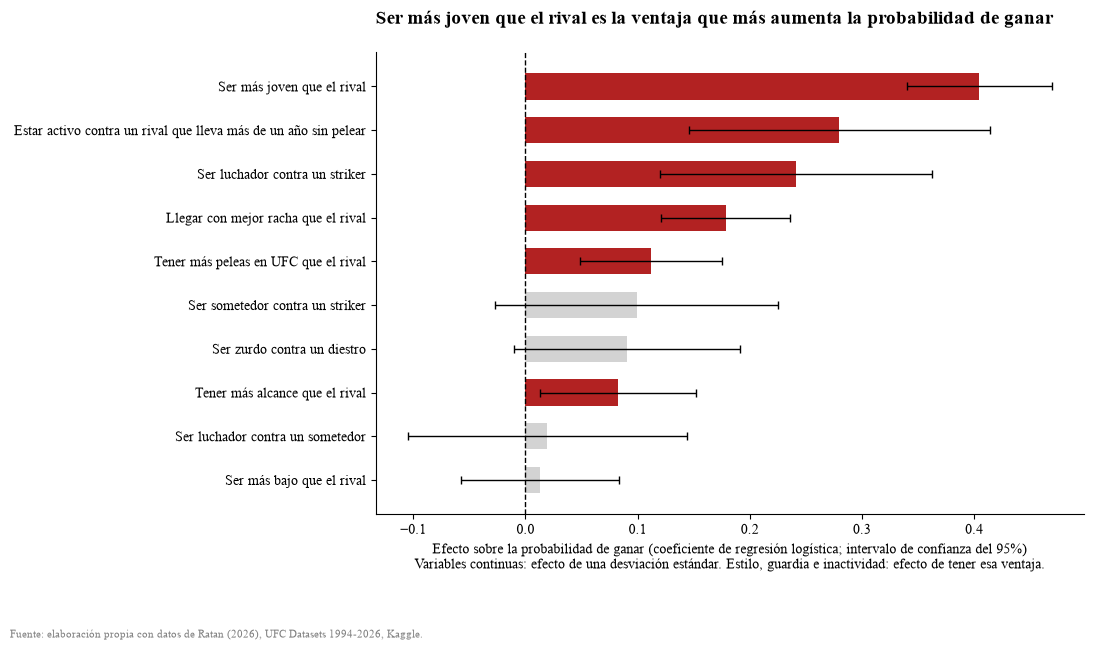

In [17]:
LABEL_FONT = 11
plt.rcParams["font.family"] = "Times New Roman"

colores = ["firebrick" if s else "lightgray" for s in grafica_coef["significativa"]]
mayor = grafica_coef.iloc[-1]
titulo = f"{mayor['etiqueta']} es la ventaja que más aumenta la probabilidad de ganar"

plt.figure(figsize=(11, 6.5))
plt.barh(grafica_coef["etiqueta"], grafica_coef["efecto"], color=colores, height=0.6)
plt.errorbar(
    grafica_coef["efecto"],
    grafica_coef["etiqueta"],
    xerr=[
        grafica_coef["efecto"] - grafica_coef["ic_inf"],
        grafica_coef["ic_sup"] - grafica_coef["efecto"],
    ],
    fmt="none",
    ecolor="black",
    capsize=3,
    linewidth=1,
)
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.title(titulo + "\n", fontsize=14, fontweight="bold", loc="left")
plt.xlabel(
    "Efecto sobre la probabilidad de ganar (coeficiente de regresión logística; intervalo de confianza del 95%)\n"
    "Variables continuas: efecto de una desviación estándar. Estilo, guardia e inactividad: efecto de tener esa ventaja.",
    fontsize=LABEL_FONT - 1,
)
plt.gca().spines[["top", "right"]].set_visible(False)
plt.figtext(
    0.01,
    0.01,
    "Fuente: elaboración propia con datos de Ratan (2026), UFC Datasets 1994-2026, Kaggle.",
    fontsize=8,
    color="gray",
)
plt.tight_layout()
plt.subplots_adjust(bottom=0.2)
plt.savefig("importancia_variables.png", dpi=300)
plt.show()